In [2]:
import numpy as np
import matplotlib.pyplot as plt

Original image (0 = black, 1 = white):
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


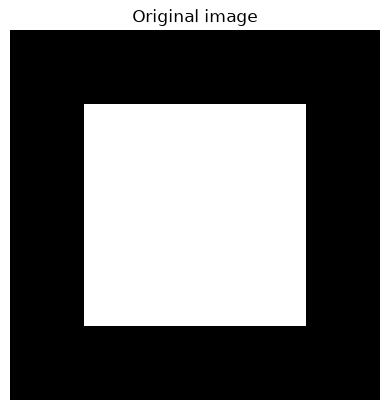

In [3]:
# a)

# 5x5 image, 0 = black, 1 = white: a 3x3 white square in the middle
original = np.zeros((5, 5), dtype=int)
original[1:4, 1:4] = 1

print("Original image (0 = black, 1 = white):")
print(original)

# vmin/vmax pin 0 to black and 1 to white, otherwise imshow rescales
plt.imshow(original, cmap="gray", vmin=0, vmax=1)
plt.title("Original image")
plt.axis("off")
plt.show()


Observed image y:
[[0 1 0 0 0]
 [0 1 1 1 1]
 [0 1 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
Pixels flipped: 3 out of 25


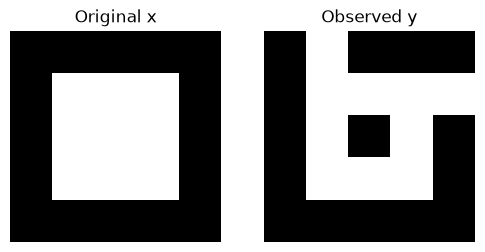

In [8]:
# b)

np.random.seed(10)

# every pixel flips 0 <-> 1 on its own, with probability 0.1
flip = np.random.rand(5, 5) < 0.1
y = np.where(flip, 1 - original, original)

print()
print("Observed image y:")
print(y)
print("Pixels flipped:", flip.sum(), "out of", y.size)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original x")
ax[0].axis("off")
ax[1].imshow(y, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Observed y")
ax[1].axis("off")
plt.show()

MRF graph: 25 nodes, 40 edges
E(y; y) with lambda = 1.0 -> 18.0
E(original; y) with lambda = 1.0 -> 15.0


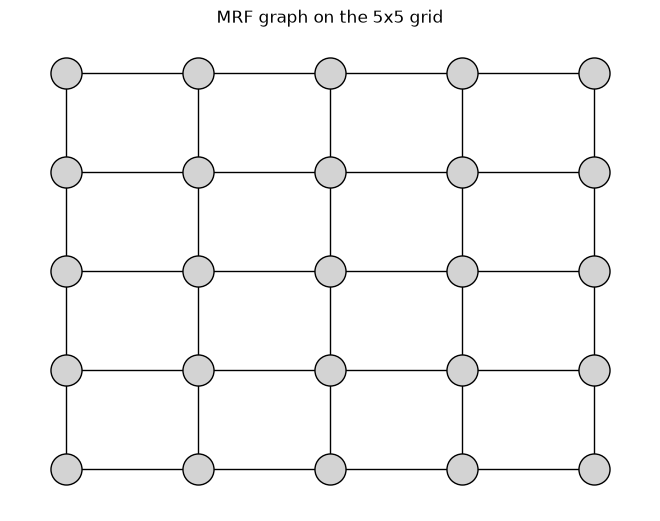

In [9]:
# c)

import networkx as nx

# the MRF graph: one node per pixel, edges only to the 4 direct neighbours
grid = nx.grid_2d_graph(5, 5)

print("MRF graph:", grid.number_of_nodes(), "nodes,", grid.number_of_edges(), "edges")


def unary(xi, yi, lam):
    return np.exp(-lam * (xi - yi) ** 2)


def pairwise(xi, xj):
    return np.exp(-(xi - xj) ** 2)


def energy(x, y, lam):
    fidelity = lam * np.sum((x - y) ** 2)
    smoothness = sum((x[a] - x[b]) ** 2 for a, b in grid.edges())
    return fidelity + smoothness


lam = 1.0
print("E(y; y) with lambda =", lam, "->", energy(y, y, lam))
print("E(original; y) with lambda =", lam, "->", energy(original, y, lam))

# draw it with the nodes in their image positions
pos = {(i, j): (j, -i) for i, j in grid.nodes()}
nx.draw(grid, pos=pos, node_size=500, node_color="lightgray", edgecolors="black")
plt.title("MRF graph on the 5x5 grid")
plt.show()

MRF{nodes: 25, edges: 40, domainSize: 10^7.5257498915995305, dim: 210}
MAP configuration x*, lambda = 1.0 , ICM converged in 2 sweeps:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
E(x*; y) = 15.0
Pixels different from the original: 0


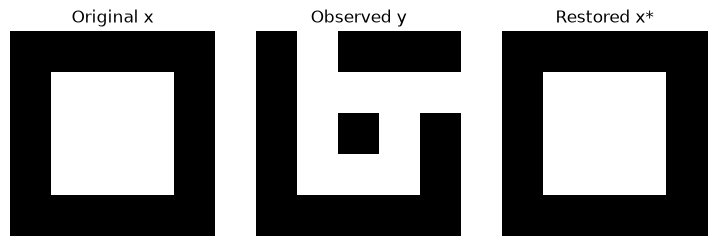

In [10]:
# d)

import pyagrum as gum

lam = 1.0

# the factors in pyAgrum: 25 unary (one per pixel) + 40 pairwise (one per edge)
mrf_img = gum.MarkovRandomField()
for (i, j) in grid.nodes():
    mrf_img.add(gum.LabelizedVariable(f"x_{i}_{j}", "", 2))

for (i, j) in grid.nodes():
    name = f"x_{i}_{j}"
    mrf_img.addFactor([name])
    for v in (0, 1):
        mrf_img.factor({name})[{name: v}] = np.exp(-lam * (v - y[i, j]) ** 2)

for a, b in grid.edges():
    na, nb = f"x_{a[0]}_{a[1]}", f"x_{b[0]}_{b[1]}"
    mrf_img.addFactor([na, nb])
    for va in (0, 1):
        for vb in (0, 1):
            mrf_img.factor({na, nb})[{na: va, nb: vb}] = np.exp(-((va - vb) ** 2))

print(mrf_img)


# ICM: one pixel at a time, pick the value that minimises the energy, others fixed
def local_energy(x, i, j, v, lam):
    e = lam * (v - y[i, j]) ** 2
    for (ni, nj) in grid.neighbors((i, j)):
        e += (v - x[ni, nj]) ** 2
    return e


def icm(lam, max_sweeps=20):
    x = y.copy()                      # start from the observed image
    for sweep in range(max_sweeps):
        changed = False
        for (i, j) in grid.nodes():
            best = int(np.argmin([local_energy(x, i, j, v, lam) for v in (0, 1)]))
            if best != x[i, j]:
                x[i, j] = best
                changed = True
        if not changed:                # nothing moved: we are at a local minimum
            return x, sweep + 1
    return x, max_sweeps


x_map, sweeps = icm(lam)

print("MAP configuration x*, lambda =", lam, ", ICM converged in", sweeps, "sweeps:")
print(x_map)
print("E(x*; y) =", energy(x_map, y, lam))
print("Pixels different from the original:", int(np.sum(x_map != original)))

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for k, (img, name) in enumerate([(original, "Original x"), (y, "Observed y"), (x_map, "Restored x*")]):
    ax[k].imshow(img, cmap="gray", vmin=0, vmax=1)
    ax[k].set_title(name)
    ax[k].axis("off")
plt.show()

lambda = 0.3 | sweeps: 2 | E(x*; y) = 12.9 | wrong pixels: 0 out of 25
lambda = 1.0 | sweeps: 2 | E(x*; y) = 15.0 | wrong pixels: 0 out of 25
lambda = 3.0 | sweeps: 2 | E(x*; y) = 17.0 | wrong pixels: 2 out of 25


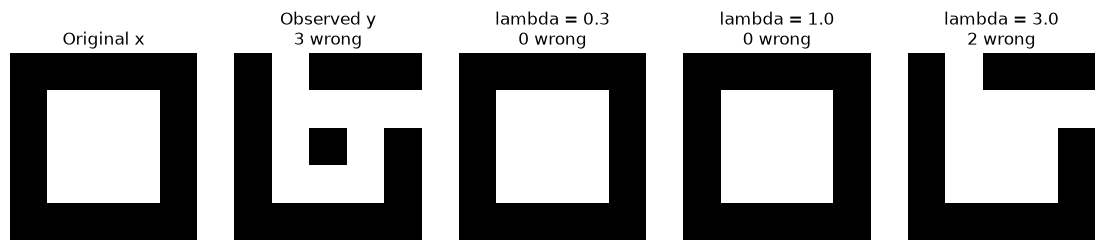

In [11]:
# e)

lambdas = [0.3, 1.0, 3.0]
results = []

# same ICM, just rerun with a different lambda each time
for lam_k in lambdas:
    x_k, sw = icm(lam_k)
    wrong = int(np.sum(x_k != original))
    results.append((lam_k, x_k, wrong))
    print("lambda =", lam_k,
          "| sweeps:", sw,
          "| E(x*; y) =", round(energy(x_k, y, lam_k), 2),
          "| wrong pixels:", wrong, "out of", original.size)

# original + observation + the three restorations, side by side
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
ax[0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original x")
ax[1].imshow(y, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Observed y\n3 wrong")
for k, (lam_k, x_k, wrong) in enumerate(results):
    ax[k + 2].imshow(x_k, cmap="gray", vmin=0, vmax=1)
    ax[k + 2].set_title("lambda = " + str(lam_k) + "\n" + str(wrong) + " wrong")
for a in ax:
    a.axis("off")
plt.show()

# e)

# lambda is the price of disagreeing with the observation, 1 is the price of
# disagreeing with a neighbour - only the ratio between them matters.
#
# for a pixel with k neighbours, of which d disagree with the observed value:
#   keeping y_i costs d,  flipping costs lambda + (k - d)
#   -> the pixel flips only if lambda < 2d - k
#
#   hole (2,2), inside the square: k=4, d=4 -> flips while lambda < 4
#   specks (0,1) and (1,4), on the border: k=3, d=2 -> flip only while lambda < 1
#   (at lambda = 1 the specks are exactly on the threshold, argmin breaks the tie
#    toward black, so they still come out repaired; from 1.1 up they survive)
#
# small lambda -> threshold easy to pass, the neighbours win, the image is smoothed
#                 (at lambda = 0 fidelity drops out entirely and the image goes uniform)
# big lambda   -> threshold hard to pass, the observation wins, the noise is kept
#                 (from lambda >= 4 nothing moves at all and x* = y)
